## Name : Seva Mundra

## SI Project

## B22-24

#### Heart Disease Prediction Using Web Scraping, Statistical Analysis and Machine Learning


In [1]:
import requests
from bs4 import BeautifulSoup

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%pip install lxml html5lib beautifulsoup4
import lxml
import html5lib

Note: you may need to restart the kernel to use updated packages.


In [2]:
url = "https://archive.ics.uci.edu/dataset/45/heart+disease"
response = requests.get(url)
print("Status Code:", response.status_code)

Status Code: 200


In [3]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)

UCI Machine Learning Repository


In [4]:
page_text = soup.get_text(" ", strip=True)

print(page_text[:3000])

UCI Machine Learning Repository Heart Disease - UCI Machine Learning Repository Datasets Contribute Dataset Donate New Link External About Us Who We Are Citation Metadata Contact Information Login Heart Disease Donated on 6/30/1988 4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach Dataset Characteristics Multivariate Subject Area Health and Medicine Associated Tasks Classification Feature Type Categorical, Integer, Real # Instances 303 # Features 13 Dataset Information Additional Information This database contains 76 attributes, but all published experiments refer to using a subset of 14 of them.  In particular, the Cleveland database is the only one that has been used by ML researchers to date.  The "goal" field refers to the presence of heart disease in the patient.  It is integer valued from 0 (no presence) to 4. Experiments with the Cleveland database have concentrated on simply attempting to distinguish presence (values 1,2,3,4) from absence (value 0).  
   
The 

In [5]:
text = soup.get_text(" ", strip=True)

keywords = [
    "Heart Disease",
    "303 Instances",
    "13 Features",
    "Missing Values"
]

for keyword in keywords:
    if keyword.lower() in text.lower():
        print("Found:", keyword)

Found: Heart Disease
Found: Missing Values


In [6]:
metadata = {
    "Dataset Name": "Heart Disease",
    "Source": "UCI Machine Learning Repository",
    "Instances": 303,
    "Features": 13,
    "Task": "Classification",
    "Missing Values": "Yes",
    "Domain": "Healthcare"
}

metadata_df = pd.DataFrame(
    metadata.items(),
    columns=["Property", "Value"]
)

metadata_df

,Property,Value
0,Dataset Name,Heart Disease
1,Source,UCI Machine Learning Repository
2,Instances,303
3,Features,13
4,Task,Classification
5,Missing Values,Yes
6,Domain,Healthcare


In [7]:
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

df = pd.read_csv(
    data_url,
    header=None,
    names=columns,
    na_values="?"
)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 303
Columns: 14


In [9]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [10]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [12]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [13]:
df.dtypes

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

In [14]:
missing = df.isnull().sum()

print(missing)

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [15]:
numeric_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [16]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "thal"
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [17]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [18]:
df["target"] = df["num"].apply(
    lambda x: 0 if x == 0 else 1
)
disease_percentage = df["target"].mean() * 100

print(
    f"Percentage of patients with heart disease: {disease_percentage:.2f}%"
)


Percentage of patients with heart disease: 45.87%


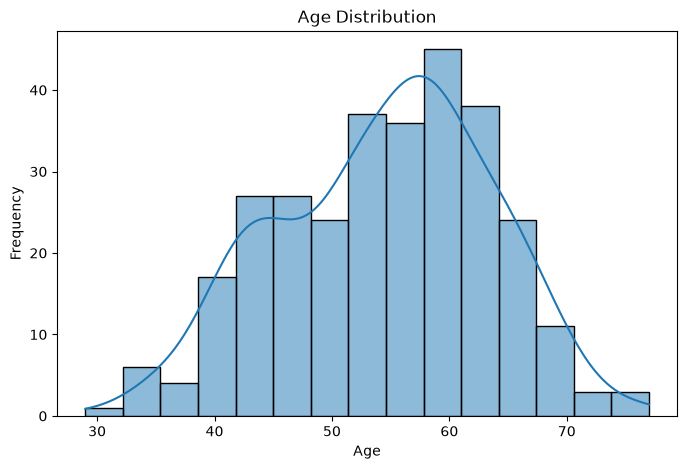

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["age"],
    bins=15,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

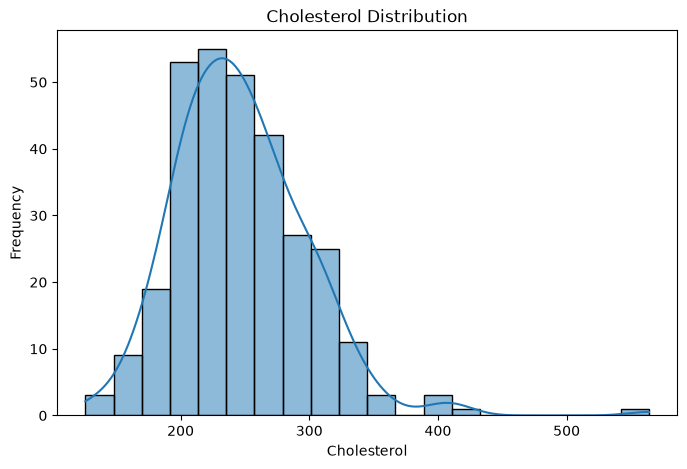

In [20]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["chol"],
    bins=20,
    kde=True
)

plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")

plt.show()

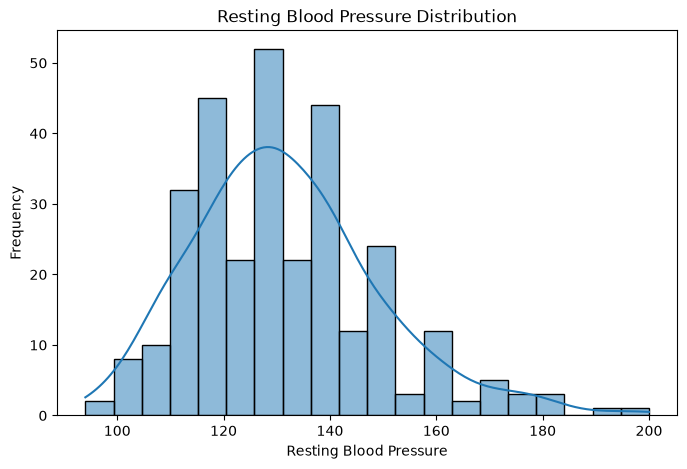

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["trestbps"],
    bins=20,
    kde=True
)

plt.title("Resting Blood Pressure Distribution")
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Frequency")

plt.show()

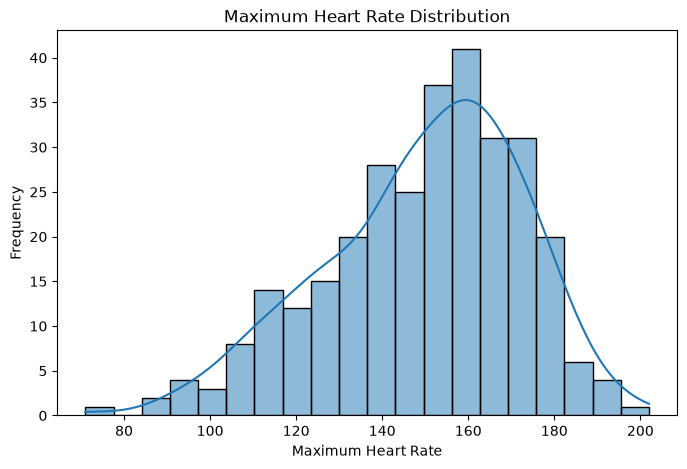

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["thalach"],
    bins=20,
    kde=True
)

plt.title("Maximum Heart Rate Distribution")
plt.xlabel("Maximum Heart Rate")
plt.ylabel("Frequency")

plt.show()

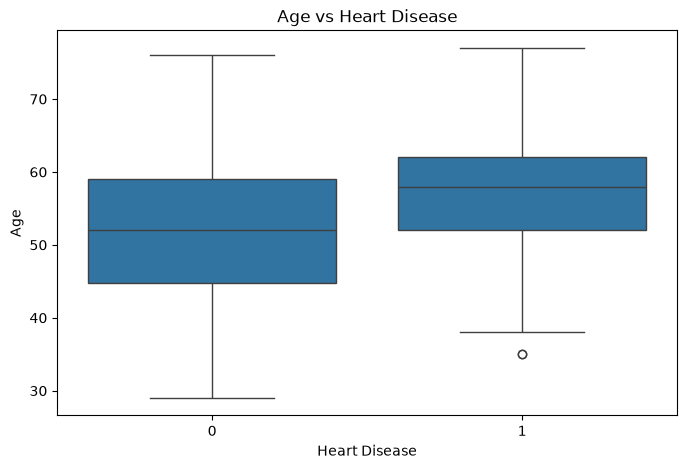

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="target",
    y="age",
    data=df
)

plt.title("Age vs Heart Disease")

plt.xlabel("Heart Disease")
plt.ylabel("Age")

plt.show()

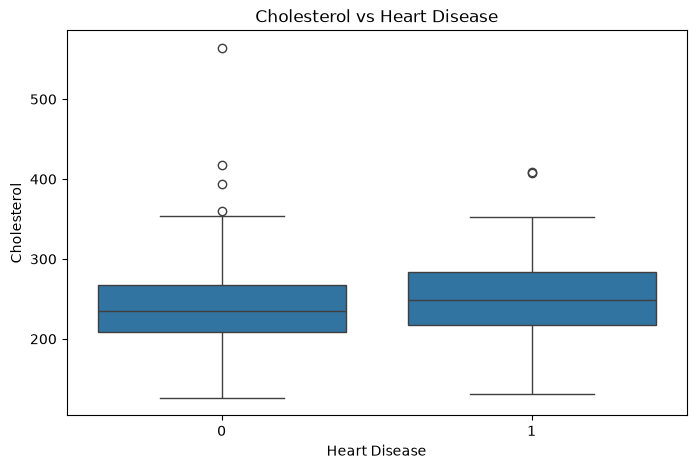

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="target",
    y="chol",
    data=df
)

plt.title("Cholesterol vs Heart Disease")

plt.xlabel("Heart Disease")
plt.ylabel("Cholesterol")

plt.show()

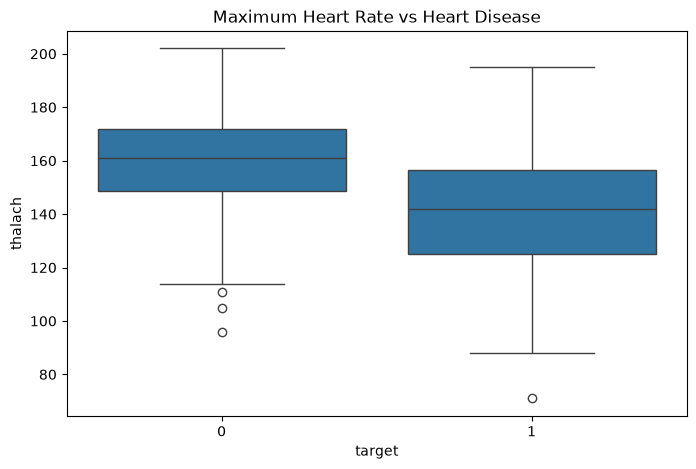

In [25]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="target",
    y="thalach",
    data=df
)

plt.title("Maximum Heart Rate vs Heart Disease")

plt.show()

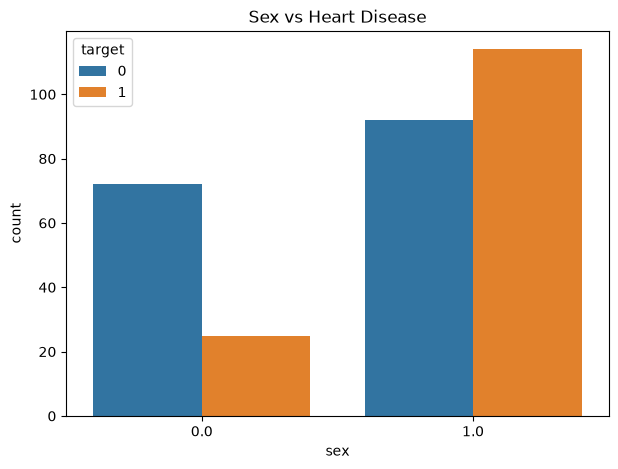

In [26]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="sex",
    hue="target",
    data=df
)

plt.title("Sex vs Heart Disease")

plt.show()

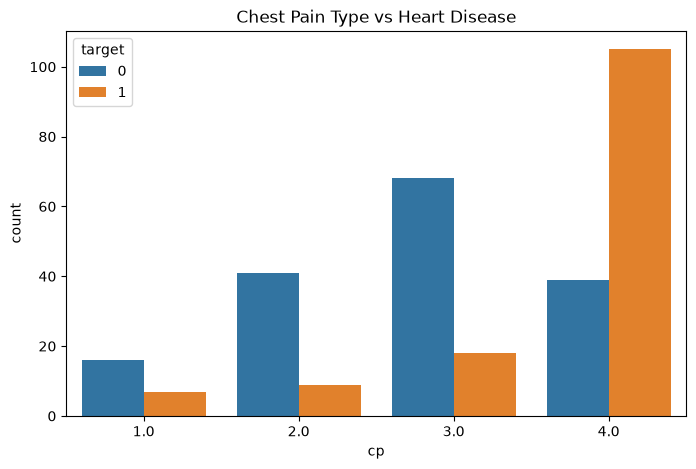

In [27]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="cp",
    hue="target",
    data=df
)

plt.title("Chest Pain Type vs Heart Disease")

plt.show()

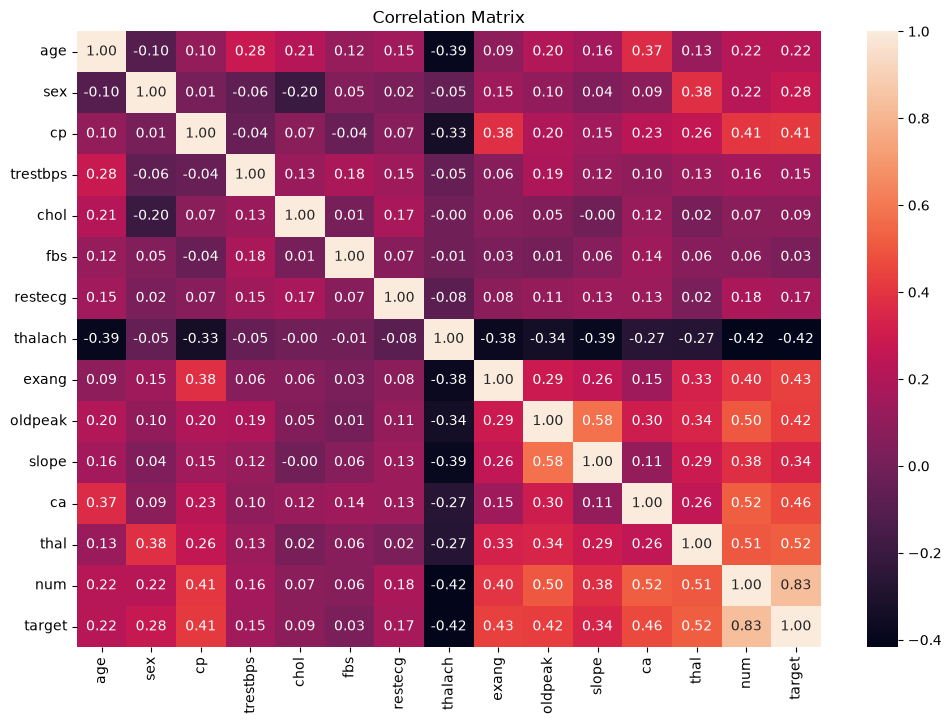

In [28]:
plt.figure(figsize=(12,8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

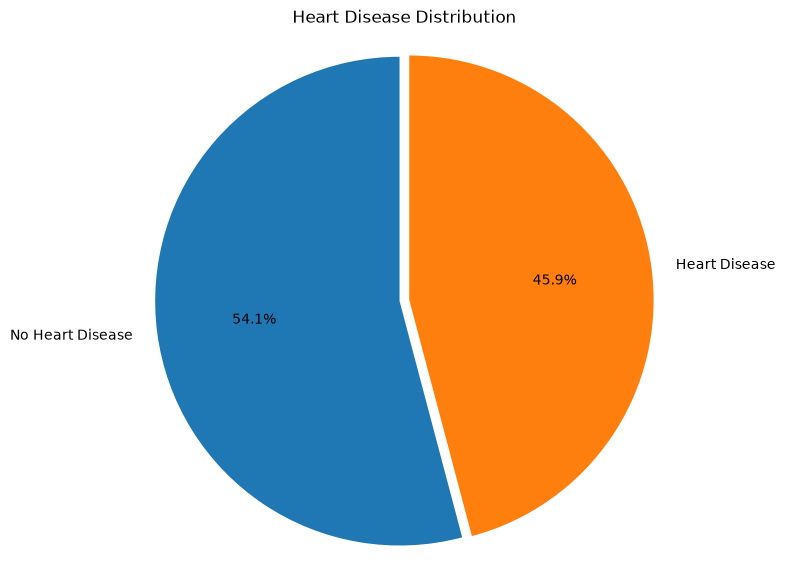

In [29]:
# Pie Chart - Heart Disease Distribution

disease_counts = df["target"].value_counts()

labels = ["No Heart Disease", "Heart Disease"]

plt.figure(figsize=(7, 7))

plt.pie(
    disease_counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.02, 0.02)
)

plt.title("Heart Disease Distribution")

plt.axis("equal")

plt.show()

In [30]:
age_mean = df["age"].mean()
age_median = df["age"].median()
age_mode = df["age"].mode()[0]

print("Mean:", age_mean)
print("Median:", age_median)
print("Mode:", age_mode)

Mean: 54.43894389438944
Median: 56.0
Mode: 58.0


In [31]:
age_variance = df["age"].var()
age_std = df["age"].std()

print("Variance:", age_variance)
print("Standard Deviation:", age_std)

Variance: 81.69741874849738
Standard Deviation: 9.038662442446746


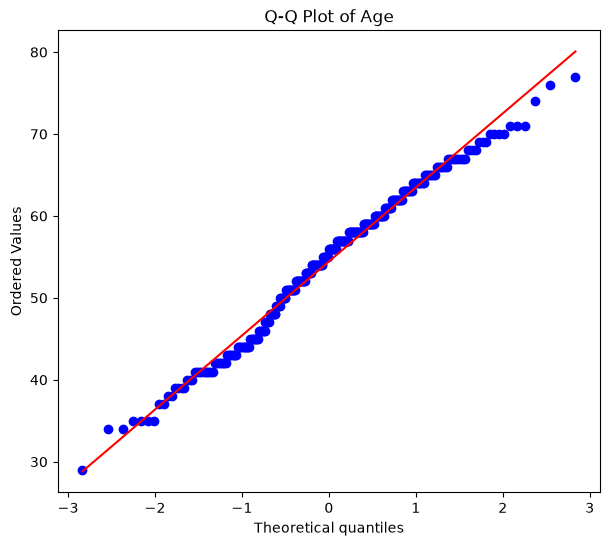

In [32]:
plt.figure(figsize=(7,6))

stats.probplot(
    df["age"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Age")

plt.show()

In [33]:
population = df.copy()

print("Population size:", len(population))

Population size: 303


In [34]:
sample_random = population.sample(
    n=50,
    random_state=42
)

print("Sample size:", len(sample_random))

Sample size: 50


In [35]:
population_mean = population["age"].mean()
sample_mean = sample_random["age"].mean()

print("Population mean:", population_mean)
print("Sample mean:", sample_mean)

Population mean: 54.43894389438944
Sample mean: 52.98


In [36]:
N = len(df)
n = 30

k = N // n

print("Population size:", N)
print("Sample size:", n)
print("Sampling interval:", k)

Population size: 303
Sample size: 30
Sampling interval: 10


In [37]:
start = np.random.randint(0, k)

systematic_sample = df.iloc[
    start::k
].head(n)

print(systematic_sample.head())
print("Sample size:", len(systematic_sample))

     age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
7   57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
17  54.0  1.0  4.0     140.0  239.0  0.0      0.0    160.0    0.0      1.2   
27  66.0  0.0  1.0     150.0  226.0  0.0      0.0    114.0    0.0      2.6   
37  57.0  1.0  4.0     150.0  276.0  0.0      2.0    112.0    1.0      0.6   
47  50.0  1.0  4.0     150.0  243.0  0.0      2.0    128.0    0.0      2.6   

    slope   ca  thal  num  target  
7     1.0  0.0   3.0    0       0  
17    1.0  0.0   3.0    0       0  
27    3.0  0.0   3.0    0       0  
37    2.0  1.0   6.0    1       1  
47    2.0  0.0   7.0    4       1  
Sample size: 30


In [38]:
from sklearn.model_selection import train_test_split

stratified_sample, _ = train_test_split(
    df,
    test_size=0.8,
    stratify=df["target"],
    random_state=42
)

print("Sample size:", len(stratified_sample))

Sample size: 60


In [39]:
print("Population:")
print(df["target"].value_counts(normalize=True))

print("\nStratified Sample:")
print(stratified_sample["target"].value_counts(normalize=True))

Population:
target
0    0.541254
1    0.458746
Name: proportion, dtype: float64

Stratified Sample:
target
0    0.533333
1    0.466667
Name: proportion, dtype: float64


In [40]:
sample_means = []

for i in range(1000):

    sample = df["age"].sample(
        n=30,
        replace=False
    )

    sample_means.append(
        sample.mean()
    )

In [41]:
sample_means = pd.Series(sample_means)

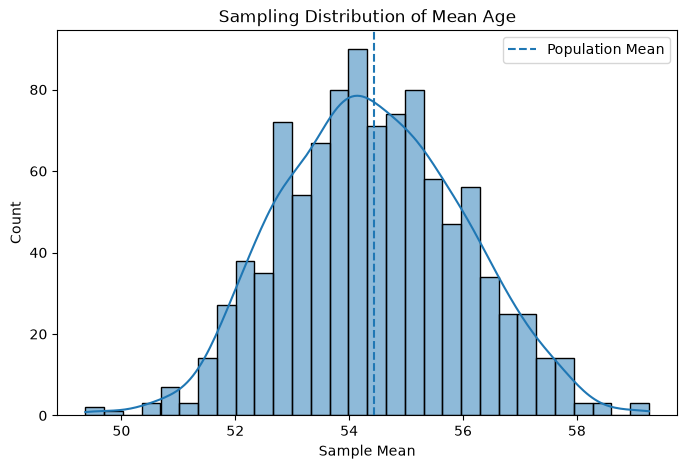

In [42]:
plt.figure(figsize=(8,5))

sns.histplot(
    sample_means,
    bins=30,
    kde=True
)

plt.axvline(
    df["age"].mean(),
    linestyle="--",
    label="Population Mean"
)

plt.title("Sampling Distribution of Mean Age")

plt.xlabel("Sample Mean")

plt.legend()

plt.show()

In [43]:
sample_sizes = [10, 30, 50, 100]
results = {}
for n in sample_sizes:
    means = []

    for i in range(1000):

        sample = df["age"].sample(
            n=n,
            replace=False
        )

        means.append(sample.mean())

    results[n] = means

In [44]:
for n in sample_sizes:

    print(
        "Sample size:",
        n,
        "Standard deviation of sample means:",
        np.std(results[n])
    )

Sample size: 10 Standard deviation of sample means: 2.813061092475597
Sample size: 30 Standard deviation of sample means: 1.5596483360752265
Sample size: 50 Standard deviation of sample means: 1.1553873530552425
Sample size: 100 Standard deviation of sample means: 0.7504204837289558


In [45]:
population_std = df["age"].std()

for n in sample_sizes:

    theoretical_se = population_std / np.sqrt(n)

    observed_se = np.std(results[n])

    print(
        f"\nSample Size: {n}"
    )

    print(
        "Theoretical SE:",
        theoretical_se
    )

    print(
        "Observed SE:",
        observed_se
    )


Sample Size: 10
Theoretical SE: 2.8582760319552305
Observed SE: 2.813061092475597

Sample Size: 30
Theoretical SE: 1.6502264364676078
Observed SE: 1.5596483360752265

Sample Size: 50
Theoretical SE: 1.2782599011820512
Observed SE: 1.1553873530552425

Sample Size: 100
Theoretical SE: 0.9038662442446747
Observed SE: 0.7504204837289558


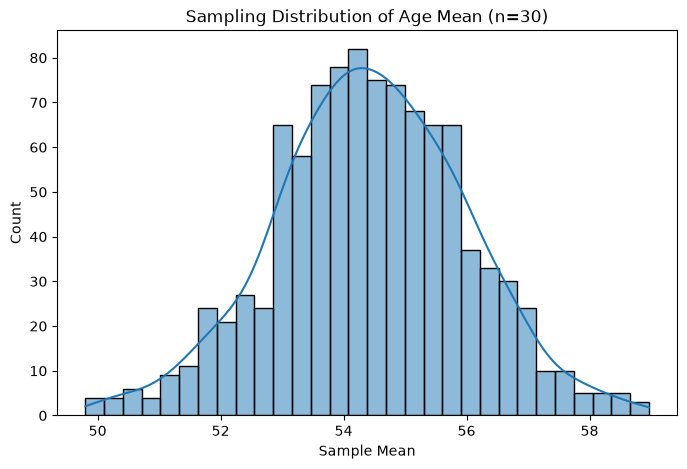

In [46]:
plt.figure(figsize=(8,5))

sns.histplot(
    results[30],
    bins=30,
    kde=True
)

plt.title(
    "Sampling Distribution of Age Mean (n=30)"
)

plt.xlabel("Sample Mean")

plt.show()

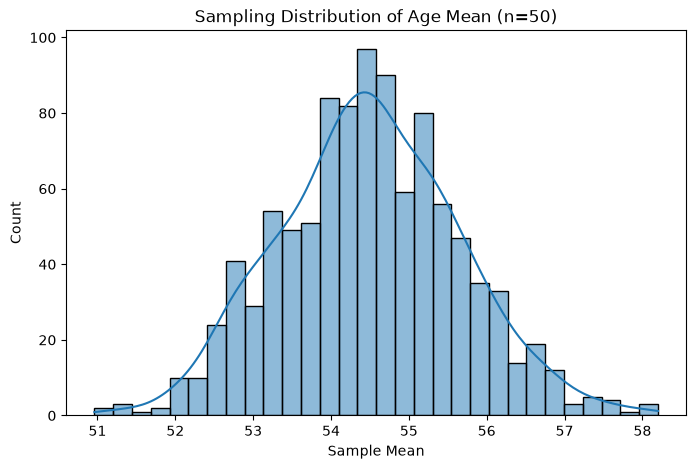

In [47]:
plt.figure(figsize=(8,5))

sns.histplot(
    results[50],
    bins=30,
    kde=True
)

plt.title(
    "Sampling Distribution of Age Mean (n=50)"
)

plt.xlabel("Sample Mean")

plt.show()

In [48]:
bootstrap_means = []

for i in range(10000):

    bootstrap_sample = df["age"].sample(
        n=len(df),
        replace=True
    )

    bootstrap_means.append(
        bootstrap_sample.mean()
    )

bootstrap_means = np.array(bootstrap_means)

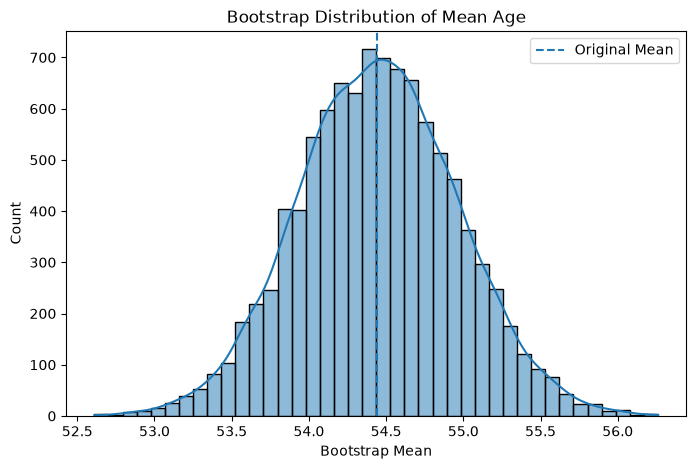

In [49]:
plt.figure(figsize=(8,5))

sns.histplot(
    bootstrap_means,
    bins=40,
    kde=True
)

plt.axvline(
    df["age"].mean(),
    linestyle="--",
    label="Original Mean"
)

plt.title("Bootstrap Distribution of Mean Age")

plt.xlabel("Bootstrap Mean")

plt.legend()

plt.show()

In [50]:
bootstrap_se = np.std(
    bootstrap_means,
    ddof=1
)

print(
    "Bootstrap Standard Error:",
    bootstrap_se
)

Bootstrap Standard Error: 0.5144971600907582


In [51]:
lower = np.percentile(
    bootstrap_means,
    2.5
)

upper = np.percentile(
    bootstrap_means,
    97.5
)

print("95% Bootstrap Confidence Interval:")
print("Lower:", lower)
print("Upper:", upper)

95% Bootstrap Confidence Interval:
Lower: 53.442244224422446
Upper: 55.47194719471947


In [52]:
bootstrap_proportions = []

for i in range(10000):

    sample = df["target"].sample(
        n=len(df),
        replace=True
    )

    bootstrap_proportions.append(
        sample.mean()
    )

bootstrap_proportions = np.array(
    bootstrap_proportions
)

In [53]:
lower = np.percentile(
    bootstrap_proportions,
    2.5
)

upper = np.percentile(
    bootstrap_proportions,
    97.5
)

print(f"Observed disease proportion: {df['target'].mean():.4f}")
print( f"95% Bootstrap CI: ({lower:.4f}, {upper:.4f})")

Observed disease proportion: 0.4587
95% Bootstrap CI: (0.4026, 0.5149)


In [54]:
disease_bootstrap_summary = {
    "Observed Disease Proportion":
        df["target"].mean(),

    "Bootstrap Mean":
        np.mean(bootstrap_proportions),

    "Bootstrap Standard Error":
        np.std(
            bootstrap_proportions,
            ddof=1
        ),

    "Lower 95% CI":
        np.percentile(
            bootstrap_proportions,
            2.5
        ),

    "Upper 95% CI":
        np.percentile(
            bootstrap_proportions,
            97.5
        )
}

disease_bootstrap_summary

{'Observed Disease Proportion': np.float64(0.45874587458745875),
 'Bootstrap Mean': np.float64(0.45857557755775585),
 'Bootstrap Standard Error': np.float64(0.028720288551285767),
 'Lower 95% CI': np.float64(0.40264026402640263),
 'Upper 95% CI': np.float64(0.5148514851485149)}

In [55]:
print("=" * 60)
print("FINAL STATISTICAL SUMMARY")
print("=" * 60)

print(f"Total observations       : {len(df)}")

print(f"Mean age                 : {df['age'].mean():.2f}")

print(f"Median age               : {df['age'].median():.2f}")

print(f"Age standard deviation   : {df['age'].std():.2f}")

print(f"Mean cholesterol         : {df['chol'].mean():.2f}")

print(f"Mean resting BP          : {df['trestbps'].mean():.2f}")

print(f"Mean maximum heart rate  : {df['thalach'].mean():.2f}")

print(f"Disease proportion       : {df['target'].mean():.2%}")

print(f"Bootstrap mean age       : {np.mean(bootstrap_means):.2f}")

print(f"Bootstrap SE             : {np.std(bootstrap_means, ddof=1):.3f}")

print(
    f"95% Bootstrap CI for age: "
    f"({np.percentile(bootstrap_means, 2.5):.2f}, "
    f"{np.percentile(bootstrap_means, 97.5):.2f})"
)

print(
    f"95% Bootstrap CI for disease proportion: "
    f"({lower:.2%}, {upper:.2%})"
)

print("=" * 60)

FINAL STATISTICAL SUMMARY
Total observations       : 303
Mean age                 : 54.44
Median age               : 56.00
Age standard deviation   : 9.04
Mean cholesterol         : 246.69
Mean resting BP          : 131.69
Mean maximum heart rate  : 149.61
Disease proportion       : 45.87%
Bootstrap mean age       : 54.45
Bootstrap SE             : 0.514
95% Bootstrap CI for age: (53.44, 55.47)
95% Bootstrap CI for disease proportion: (40.26%, 51.49%)


# Conclusion

The UCI Heart Disease dataset was successfully analyzed using a complete statistical workflow beginning with web-based data acquisition and continuing through data preprocessing, exploratory data analysis, probability distribution analysis, sampling, the Central Limit Theorem and bootstrap resampling.

The visualization and correlation analysis provided insight into relationships among the patient variables. Different sampling techniques demonstrated how representative samples can be obtained from a population, while repeated sampling showed the variability of sample statistics.

The Central Limit Theorem experiment demonstrated that increasing the sample size reduces the variability of the sampling distribution of the mean. Bootstrap resampling further demonstrated how confidence intervals and uncertainty can be estimated directly from the available data without requiring strong assumptions about the underlying population distribution.

Overall, the project demonstrates the practical application of statistical concepts to a real-world healthcare dataset and shows how sampling and resampling methods can be used to understand uncertainty in statistical estimates.

# Practical 5 — Confidence Intervals and Hypothesis Testing
This section uses the existing UCI Heart Disease dataset. The examples analyze patient age and compare mean age with a stated reference value. Run after the dataset has been loaded, missing values handled, and `df["target"]` created.

In [56]:
# Mean, standard deviation, standard error and 95% confidence interval for age
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

age = df["age"].dropna()
n = len(age)
mean_age = age.mean()
sd_age = age.std(ddof=1)
se_age = stats.sem(age)
confidence = 0.95
t_critical = stats.t.ppf((1 + confidence) / 2, df=n - 1)
margin_error = t_critical * se_age
ci_lower, ci_upper = mean_age - margin_error, mean_age + margin_error

print("Sample size:", n)
print(f"Mean age: {mean_age:.2f}")
print(f"Standard deviation: {sd_age:.2f}")
print(f"Standard error: {se_age:.3f}")
print(f"T critical value (95% CI): {t_critical:.3f}")
print(f"Margin of error: {margin_error:.3f}")
print(f"95% confidence interval: ({ci_lower:.2f}, {ci_upper:.2f})")

Sample size: 303
Mean age: 54.44
Standard deviation: 9.04
Standard error: 0.519
T critical value (95% CI): 1.968
Margin of error: 1.022
95% confidence interval: (53.42, 55.46)


In [57]:
# Z critical value and confidence interval using a normal approximation
z_critical = stats.norm.ppf(0.975)
z_margin_error = z_critical * sd_age / np.sqrt(n)
z_ci = (mean_age - z_margin_error, mean_age + z_margin_error)
print("Z critical value for 95% confidence:", round(z_critical, 3))
print("Z-based 95% confidence interval:", tuple(round(x, 2) for x in z_ci))
print("Note: population standard deviation is usually unknown, so the t interval is generally preferred.")

Z critical value for 95% confidence: 1.96
Z-based 95% confidence interval: (np.float64(53.42), np.float64(55.46))
Note: population standard deviation is usually unknown, so the t interval is generally preferred.


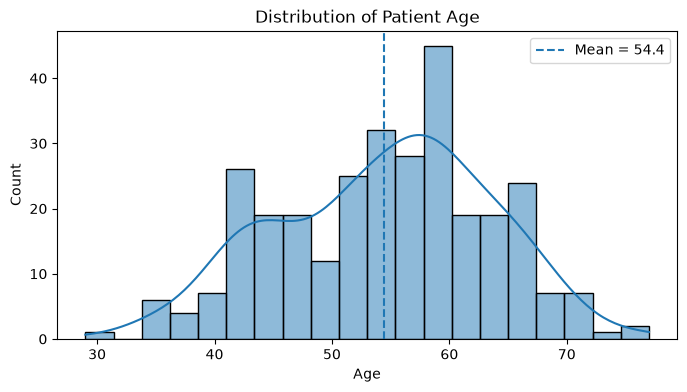

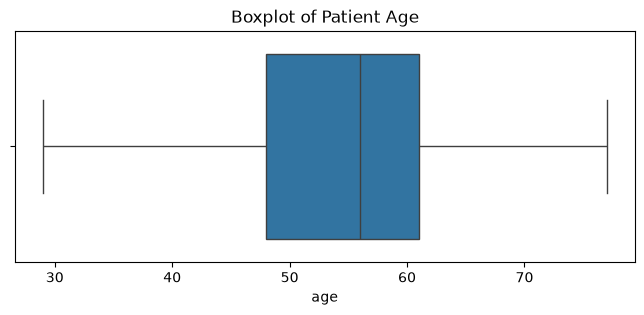

In [58]:
# Histogram and boxplot for age
plt.figure(figsize=(8, 4))
sns.histplot(age, bins=20, kde=True)
plt.axvline(mean_age, linestyle="--", label=f"Mean = {mean_age:.1f}")
plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.legend()
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(x=age)
plt.title("Boxplot of Patient Age")
plt.show()

In [59]:
# One-sample t-test
# H0: population mean age = 50
reference_mean = 50
t_stat, p_value = stats.ttest_1samp(age, popmean=reference_mean)
alpha = 0.05
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(p_value, 6))
print("Significance level:", alpha)
if p_value < alpha:
    print("Decision: Reject H0. The mean age is statistically different from 50.")
else:
    print("Decision: Fail to reject H0. There is not enough evidence that the mean age differs from 50.")

t-statistic: 8.5486
p-value: 0.0
Significance level: 0.05
Decision: Reject H0. The mean age is statistically different from 50.


In [60]:
# One-sample Z-test (large-sample approximation using sample SD)
# H0: mean age = 50; two-sided test
z_stat = (mean_age - reference_mean) / (sd_age / np.sqrt(n))
z_p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print("Z statistic:", round(z_stat, 4))
print("Z-test p-value:", round(z_p_value, 6))
print("Decision:", "Reject H0" if z_p_value < alpha else "Fail to reject H0")
print("Teaching note: a true one-sample Z-test assumes the population SD is known; this example uses sample SD as an approximation.")

Z statistic: 8.5486
Z-test p-value: 0.0
Decision: Reject H0
Teaching note: a true one-sample Z-test assumes the population SD is known; this example uses sample SD as an approximation.


# Practical 6 — Independent and Paired T-Tests
The independent test compares two separate groups in the real dataset: patients with and without heart disease. The paired test requires before-and-after measurements from the same people; this dataset has no such pair, so the second example uses clearly labeled demonstration data.

Heart disease group mean age: 56.63
No heart disease group mean age: 52.59
Welch t-statistic: 4.0303
p-value: 7.1e-05
Decision: Reject H0: evidence of a difference in mean age


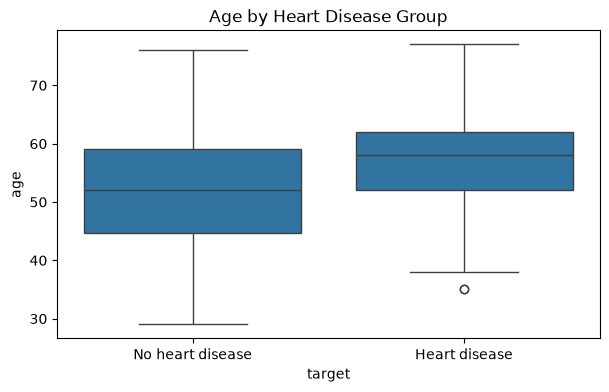

In [61]:
# Independent two-sample t-test: age of patients with vs without heart disease
# H0: the two groups have equal population mean age
# H1: the population mean ages differ
group_no = df.loc[df["target"] == 0, "age"].dropna()
group_yes = df.loc[df["target"] == 1, "age"].dropna()
t_ind, p_ind = stats.ttest_ind(group_yes, group_no, equal_var=False)  # Welch's t-test
print("Heart disease group mean age:", round(group_yes.mean(), 2))
print("No heart disease group mean age:", round(group_no.mean(), 2))
print("Welch t-statistic:", round(t_ind, 4))
print("p-value:", round(p_ind, 6))
print("Decision:", "Reject H0: evidence of a difference in mean age" if p_ind < 0.05 else "Fail to reject H0: insufficient evidence of a difference")
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="target", y="age")
plt.xticks([0, 1], ["No heart disease", "Heart disease"])
plt.title("Age by Heart Disease Group")
plt.show()

In [62]:
# Paired t-test demonstration (illustrative data only; not from the heart dataset)
# Each before/after value represents the same person's measurement.
before = np.array([72, 80, 75, 90, 68, 85, 78, 82])
after  = np.array([70, 77, 73, 86, 67, 81, 75, 80])
t_paired, p_paired = stats.ttest_rel(before, after)
print("Before mean:", round(before.mean(), 2))
print("After mean:", round(after.mean(), 2))
print("Paired t-statistic:", round(t_paired, 4))
print("p-value:", round(p_paired, 6))
print("Decision:", "Reject H0: evidence of a before-after difference" if p_paired < 0.05 else "Fail to reject H0: insufficient evidence of a before-after difference")
print("Important: replace these illustrative values with genuine matched measurements for a real study.")

Before mean: 78.75
After mean: 76.12
Paired t-statistic: 7.0
p-value: 0.000212
Decision: Reject H0: evidence of a before-after difference
Important: replace these illustrative values with genuine matched measurements for a real study.


# Practical 7 — Simple Linear Regression
For this heart-disease project, the simple regression example predicts `thalach` (maximum recorded heart rate) from `age`. This keeps the code consistent with the dataset already loaded in this notebook.

In [63]:
# Prepare data, split, and scale the single predictor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

simple_data = df[["age", "thalach"]].dropna()
X_simple = simple_data[["age"]]
y_simple = simple_data["thalach"]
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)
scaler_simple = StandardScaler()
X_train_s_scaled = scaler_simple.fit_transform(X_train_s)
X_test_s_scaled = scaler_simple.transform(X_test_s)
print("Training rows:", len(X_train_s), "| Test rows:", len(X_test_s))

Training rows: 242 | Test rows: 61


In [64]:
# Train and compare five regression models
simple_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}
simple_results = []
simple_fitted = {}
for name, model in simple_models.items():
    # Scaling is applied to every model here for a consistent workflow
    model.fit(X_train_s_scaled, y_train_s)
    pred = model.predict(X_test_s_scaled)
    mse = mean_squared_error(y_test_s, pred)
    simple_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_s, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test_s, pred)
    })
    simple_fitted[name] = model
simple_results_df = pd.DataFrame(simple_results).sort_values("RMSE")
display(simple_results_df)
best_simple_name = simple_results_df.iloc[0]["Model"]
best_simple_model = simple_fitted[best_simple_name]
print("Best model by lowest RMSE:", best_simple_name)

,Model,MAE,MSE,RMSE,R2
2,Lasso Regression,19.327857,549.364427,23.438524,0.070263
1,Ridge Regression,19.350050,552.413258,23.503473,0.065103
0,Linear Regression,19.350948,552.572933,23.506870,0.064833
3,Decision Tree,20.561207,576.867598,24.018068,0.023717
4,Random Forest,21.432195,618.916346,24.878029,-0.047446


Best model by lowest RMSE: Lasso Regression


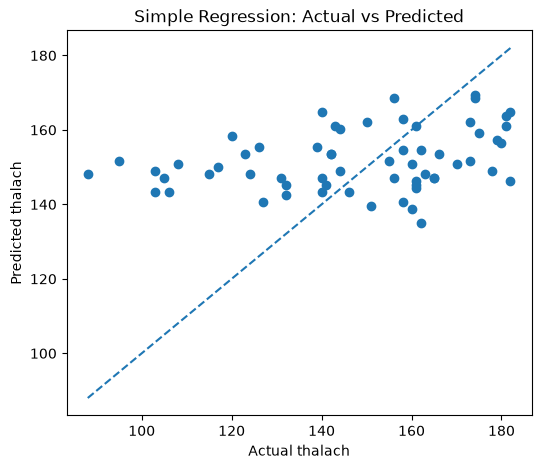

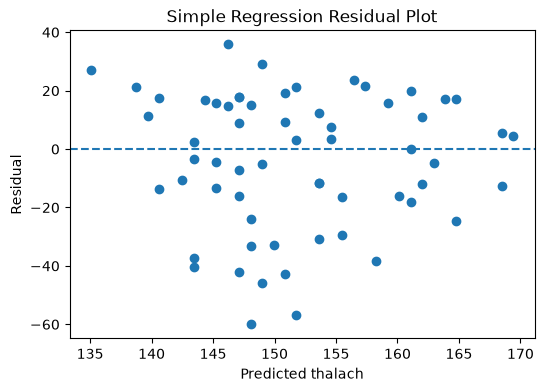

In [65]:
best_simple_pred = best_simple_model.predict(X_test_s_scaled)
plt.figure(figsize=(6, 5))
plt.scatter(y_test_s, best_simple_pred)
low = min(y_test_s.min(), best_simple_pred.min())
high = max(y_test_s.max(), best_simple_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual thalach")
plt.ylabel("Predicted thalach")
plt.title("Simple Regression: Actual vs Predicted")
plt.show()

residuals_s = y_test_s.to_numpy() - best_simple_pred
plt.figure(figsize=(6, 4))
plt.scatter(best_simple_pred, residuals_s)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted thalach")
plt.ylabel("Residual")
plt.title("Simple Regression Residual Plot")
plt.show()

In [66]:
# Save selected simple model and its scaler
joblib.dump(best_simple_model, "best_simple_regression_model.pkl")
joblib.dump(scaler_simple, "simple_regression_scaler.pkl")
print("Saved: best_simple_regression_model.pkl and simple_regression_scaler.pkl")

# Example: load the files and predict maximum heart rate for age 45
loaded_simple_model = joblib.load("best_simple_regression_model.pkl")
loaded_simple_scaler = joblib.load("simple_regression_scaler.pkl")
example_age = pd.DataFrame({"age": [45]})
example_age_scaled = loaded_simple_scaler.transform(example_age)
print("Predicted thalach for age 45:", round(float(loaded_simple_model.predict(example_age_scaled)[0]), 2))

Saved: best_simple_regression_model.pkl and simple_regression_scaler.pkl
Predicted thalach for age 45: 159.21


# Practical 8 — Multiple Linear Regression
This section predicts `thalach` using three input features: `age`, `trestbps`, and `chol`. Model comparison uses the same MAE, MSE, RMSE, and R² metrics.

In [67]:
multi_features = ["age", "trestbps", "chol"]
multi_target = "thalach"
multi_data = df[multi_features + [multi_target]].dropna()
X_multi = multi_data[multi_features]
y_multi = multi_data[multi_target]
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)
scaler_multi = StandardScaler()
X_train_m_scaled = scaler_multi.fit_transform(X_train_m)
X_test_m_scaled = scaler_multi.transform(X_test_m)
print("Features:", multi_features)
print("Training rows:", len(X_train_m), "| Test rows:", len(X_test_m))

Features: ['age', 'trestbps', 'chol']
Training rows: 242 | Test rows: 61


In [68]:

multi_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}
multi_results = []
multi_fitted = {}
for name, model in multi_models.items():
    model.fit(X_train_m_scaled, y_train_m)
    pred = model.predict(X_test_m_scaled)
    mse = mean_squared_error(y_test_m, pred)
    multi_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_m, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test_m, pred)
    })
    multi_fitted[name] = model
multi_results_df = pd.DataFrame(multi_results).sort_values("RMSE")
display(multi_results_df)
best_multi_name = multi_results_df.iloc[0]["Model"]
best_multi_model = multi_fitted[best_multi_name]
print("Best model by lowest RMSE:", best_multi_name)

,Model,MAE,MSE,RMSE,R2
2,Lasso Regression,19.327937,550.481612,23.462345,0.068372
1,Ridge Regression,19.196091,554.768583,23.553526,0.061117
0,Linear Regression,19.194450,555.036130,23.559205,0.060664
4,Random Forest,20.311148,602.500446,24.545885,-0.019664
3,Decision Tree,21.132964,644.344400,25.383940,-0.090480


Best model by lowest RMSE: Lasso Regression


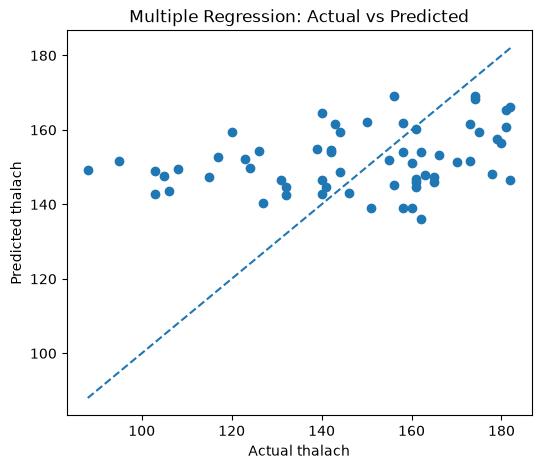

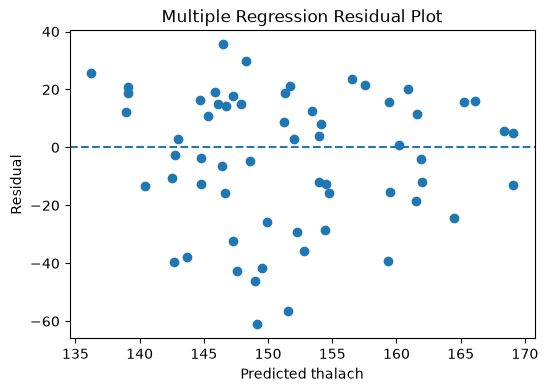

In [69]:

best_multi_pred = best_multi_model.predict(X_test_m_scaled)
plt.figure(figsize=(6, 5))
plt.scatter(y_test_m, best_multi_pred)
low = min(y_test_m.min(), best_multi_pred.min())
high = max(y_test_m.max(), best_multi_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual thalach")
plt.ylabel("Predicted thalach")
plt.title("Multiple Regression: Actual vs Predicted")
plt.show()

residuals_m = y_test_m.to_numpy() - best_multi_pred
plt.figure(figsize=(6, 4))
plt.scatter(best_multi_pred, residuals_m)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted thalach")
plt.ylabel("Residual")
plt.title("Multiple Regression Residual Plot")
plt.show()

In [70]:
joblib.dump(best_multi_model, "best_multiple_regression_model.pkl")
joblib.dump(scaler_multi, "multiple_regression_scaler.pkl")
print("Saved: best_multiple_regression_model.pkl and multiple_regression_scaler.pkl")

loaded_multi_model = joblib.load("best_multiple_regression_model.pkl")
loaded_multi_scaler = joblib.load("multiple_regression_scaler.pkl")
example_patient = pd.DataFrame({"age": [45], "trestbps": [130], "chol": [240]})
example_patient_scaled = loaded_multi_scaler.transform(example_patient[multi_features])
prediction = loaded_multi_model.predict(example_patient_scaled)[0]
print(f"Predicted maximum heart rate (thalach): {prediction:.2f}")

Saved: best_multiple_regression_model.pkl and multiple_regression_scaler.pkl
Predicted maximum heart rate (thalach): 159.41


In [71]:
!pip install gradio

In [72]:
# Optional Gradio interface for the multiple-feature model
# Run this cell only if Gradio is installed in the notebook environment.
try:
    import gradio as gr

    def predict_thalach(age, trestbps, chol):
        sample = pd.DataFrame([{
            "age": age,
            "trestbps": trestbps,
            "chol": chol
        }], columns=multi_features)
        sample_scaled = loaded_multi_scaler.transform(sample)
        result = loaded_multi_model.predict(sample_scaled)[0]
        return round(float(result), 2)

    demo = gr.Interface(
        fn=predict_thalach,
        inputs=[
            gr.Number(label="Age", value=45),
            gr.Number(label="Resting blood pressure (trestbps)", value=130),
            gr.Number(label="Cholesterol (chol)", value=240)
        ],
        outputs=gr.Number(label="Predicted maximum heart rate (thalach)"),
        title="Heart Data — Regression Demo",
        description="Educational regression demo only; not a medical diagnosis."
    )
    print("Gradio interface created. Uncomment demo.launch() below to launch it.")
    demo.launch()
except ImportError:
    print("Gradio is not installed. Install it with: %pip install gradio")

Gradio interface created. Uncomment demo.launch() below to launch it.
* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


## Streamlit Web App

This section adds a simple Streamlit interface for the multiple-feature regression model above. It predicts `thalach` using `age`, `trestbps`, and `chol`. The app is an educational demonstration, not a medical diagnosis.

### 1. Save the trained model files
Run the model-training and saving cells above (cells 74–77 in the notebook). They create:
- `best_multiple_regression_model.pkl`
- `multiple_regression_scaler.pkl`

Download both files from the notebook environment and keep them in the same folder as `app.py`.

### 2. Install Streamlit
Run this in your computer terminal / Command Prompt (not as a Python statement):
`pip install streamlit pandas scikit-learn joblib`

### 3. Run the app
Keep `app.py` and both `.pkl` files in one folder, open a terminal in that folder, and run:
`streamlit run app.py`

Streamlit will print a local URL, usually `http://localhost:8501`, to open in your browser.

**Note:** Streamlit is designed to run as a local app or be deployed on a hosting service. `app.py` is provided as a separate file because a notebook cell alone does not launch a persistent Streamlit web app reliably.


In [147]:
# Optional: install Streamlit in the current notebook environment
%pip install streamlit

# The Streamlit app is provided separately as app.py.
# For local use, download app.py and the two model files saved in cells 74–77,
# then run: streamlit run app.py


Note: you may need to restart the kernel to use updated packages.
